#Bagian 3. Operasi Morfologi pada Citra Biner

## Langkah 3.1 Lembar hitung manual

In [49]:

import cv2
import numpy as np
import pandas as pd

# Citra biner B berukuran 9 x 9
B = np.array([
    [0,0,0,0,0,0,0,0,0],
    [0,1,1,1,0,0,0,0,0],
    [0,1,0,1,0,0,0,1,0],
    [0,1,1,1,0,0,0,0,0],
    [0,0,0,0,1,0,0,0,0],
    [0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0],
    [0,1,1,1,1,1,1,0,0],
    [0,0,0,0,0,0,0,0,0]
], dtype=np.uint8)

# Structuring Element persegi 3 x 3
SE = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Menghitung komponen terhubung
def jumlah_komponen(mask, konektivitas):
    jumlah, _ = cv2.connectedComponents(
        mask.astype(np.uint8),
        connectivity=konektivitas
    )
    return jumlah - 1

# Operasi morfologi dengan batas luar bernilai 0
def erosi(mask):
    return cv2.erode(mask, SE, borderType=cv2.BORDER_CONSTANT,
                     borderValue=0)

def dilasi(mask):
    return cv2.dilate(mask, SE, borderType=cv2.BORDER_CONSTANT,
                      borderValue=0)

# a. Komponen terhubung
komponen_4 = jumlah_komponen(B, 4)
komponen_8 = jumlah_komponen(B, 8)

# b. Erosi dan opening
hasil_erosi = erosi(B)
hasil_opening = dilasi(hasil_erosi)

# c. Closing
hasil_dilasi = dilasi(B)
hasil_closing = erosi(hasil_dilasi)

# d. Closing dilanjutkan opening
hasil_closing_opening = dilasi(erosi(hasil_closing))

# Menampilkan matriks
def tampil_matriks(nama, matriks):
    print(f"\n{nama}")
    print(np.array2string(matriks, separator=" "))

print("=== LEMBAR HITUNG 3.1 ===")

print("\na. JUMLAH KOMPONEN TERHUBUNG")
print("Konektivitas 4 :", komponen_4)
print("Konektivitas 8 :", komponen_8)

print("\nb. HASIL OPERASI EROSI DAN OPENING")
tampil_matriks("Erosi B:", hasil_erosi)
tampil_matriks("Opening B:", hasil_opening)

print("\nc. HASIL OPERASI CLOSING")
tampil_matriks("Closing B:", hasil_closing)

print("\nd. CLOSING DILANJUTKAN OPENING")
tampil_matriks("Closing + Opening:", hasil_closing_opening)

# Ringkasan jumlah piksel aktif
print("\n=== RINGKASAN JUMLAH PIXEL AKTIF ===")
for nama, hasil in [
    ("Awal", B),
    ("Erosi", hasil_erosi),
    ("Opening", hasil_opening),
    ("Closing", hasil_closing),
    ("Closing + Opening", hasil_closing_opening)
]:
    print(f"{nama:20s}: {np.count_nonzero(hasil)} piksel")


=== LEMBAR HITUNG 3.1 ===

a. JUMLAH KOMPONEN TERHUBUNG
Konektivitas 4 : 4
Konektivitas 8 : 3

b. HASIL OPERASI EROSI DAN OPENING

Erosi B:
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

Opening B:
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

c. HASIL OPERASI CLOSING

Closing B:
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]

d. CLOSING DILANJUTKAN OPENING

Closing + Opening:
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]

## Langkah 3.2 Citra biner awal.
### Kode 3.1 Mask daun awal dan bercak awal

In [50]:

# =====================================================
# P6 - OPERASI MORFOLOGI DAN KOMPONEN TERHUBUNG
# Persiapan Google Colab
# =====================================================

# 1. Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Import library
import os
import sys
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

# 3. Tentukan folder proyek
ROOT = "/content/drive/MyDrive/simuteh-2330511004"
os.chdir(ROOT)

DATA = os.path.join(ROOT, "data", "sintetis")
CITRA = os.path.join(DATA, "citra")
LABEL = os.path.join(DATA, "label.csv")
HASIL = os.path.join(ROOT, "hasil")
SRC = os.path.join(ROOT, "src")

# 4. Hubungkan modul
sys.path.insert(0, SRC)

from utils_cv import baca, tampil
from praproses import praproses

# 5. Muat parameter praproses
with open(os.path.join(HASIL, "param_praproses.json"), "r") as f:
    PARAM = json.load(f)

# 6. Muat label dataset
label = pd.read_csv(LABEL)

# 7. Periksa file modul yang tersedia
print("=== PERSIAPAN P6 ===")
print("Folder proyek :", ROOT)
print("Jumlah data   :", len(label))
print("OpenCV        :", cv2.__version__)
print("Isi folder src:", os.listdir(SRC))
print("Parameter     :", PARAM)
print("\nPersiapan awal P6 selesai.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== PERSIAPAN P6 ===
Folder proyek : /content/drive/MyDrive/simuteh-2330511004
Jumlah data   : 60
OpenCV        : 5.0.0
Isi folder src: ['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__', 'praproses.py', 'praproses_acuan.py', 'utils_tepi.py', 'bercak.py']
Parameter     : {'lebar': 640, 'gamma': 'auto', 'clahe_clip': 1.0, 'clahe_tile': 4, 'clahe_otomatis': True, 'batas_tidak_rata': 0.65, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}

Persiapan awal P6 selesai.


In [51]:

def muat(nama):
    img = cv2.imread(os.path.join(CITRA, nama))
    md = cv2.imread(
        os.path.join(DATA, "mask_daun", nama),
        cv2.IMREAD_GRAYSCALE
    )
    mb = cv2.imread(
        os.path.join(DATA, "mask_bercak", nama),
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {nama}")
    if md is None:
        raise FileNotFoundError(f"Mask daun tidak ditemukan: {nama}")
    if mb is None:
        raise FileNotFoundError(f"Mask bercak tidak ditemukan: {nama}")

    return img, md, mb


# 2. Fungsi IoU sesuai Lampiran A PDF
def iou(a, b):
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


# 3. Fungsi membuat mask daun awal
def mask_daun_awal(img_bgr):
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(
        s, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    return m


# 4. Fungsi membuat mask bercak awal
def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0

    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))

    return (((c > med + k * mad) & m) * 255).astype(np.uint8)

def tepi_canny(gray, bawah=50, atas=150):
    return cv2.Canny(gray, bawah, atas)


print("Fungsi muat, iou, mask_daun_awal, dan bercak_awal berhasil dibuat.")


Fungsi muat, iou, mask_daun_awal, dan bercak_awal berhasil dibuat.


         citra  IoU daun awal  komponen bercak awal  komponen acuan  \
0  teh_041.png          0.996                   159               8   
1  teh_021.png          0.997                   217               3   
2  teh_011.png          0.998                   134               0   

  IoU bercak awal  
0           0.664  
1           0.384  
2               -  


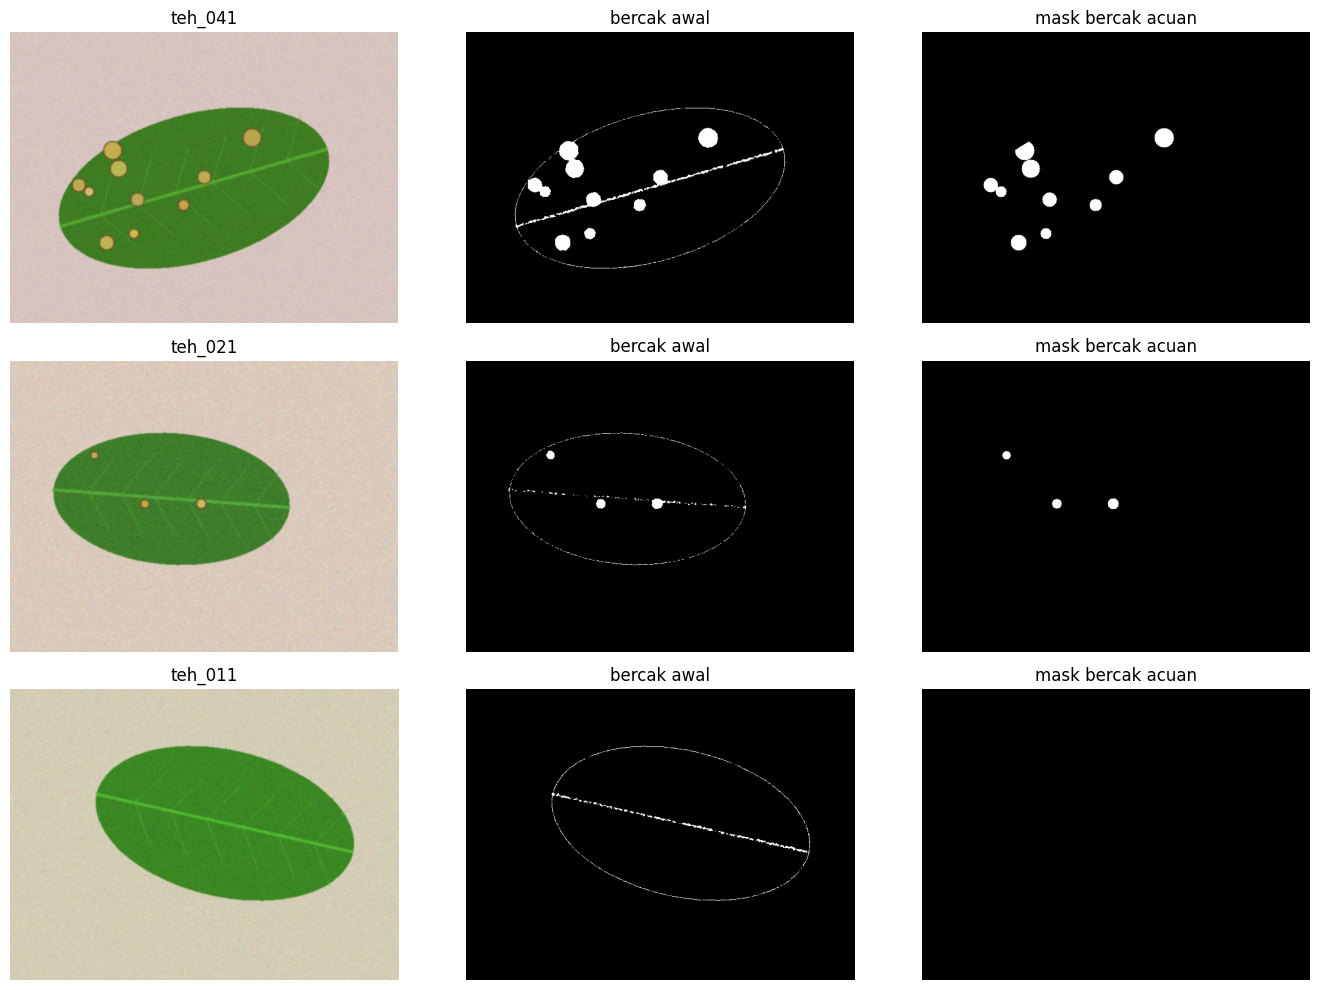

In [52]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )[0] - 1


baris, panel, judul = [], [], []
# berat, ringan, sehat
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)

    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])

    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(
    baris,
    columns=[
        "citra",
        "IoU daun awal",
        "komponen bercak awal",
        "komponen acuan",
        "IoU bercak awal"
    ]
))

tampil(panel, judul, baris=3, ukuran=(14, 10))

## Langkah 3.3 Enam operasi.
### Kode 3.2 Erosi, dilasi, opening, dan closing

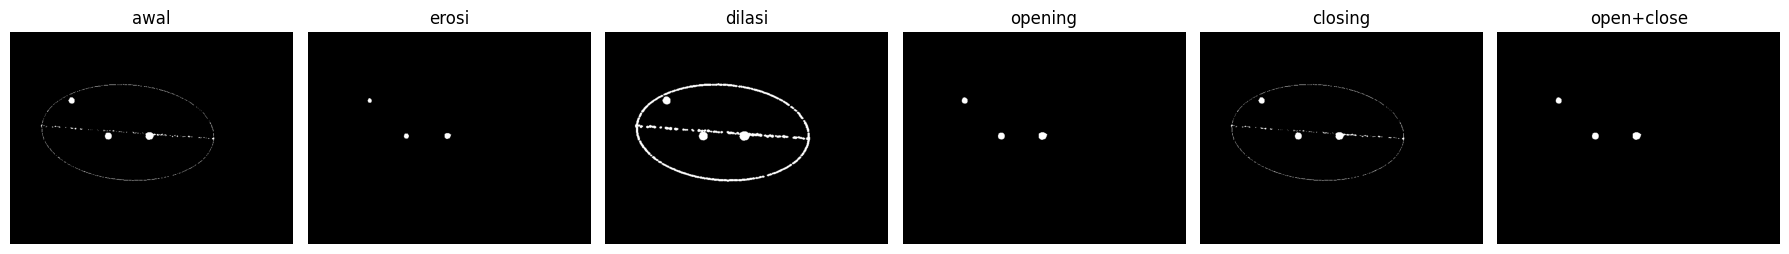

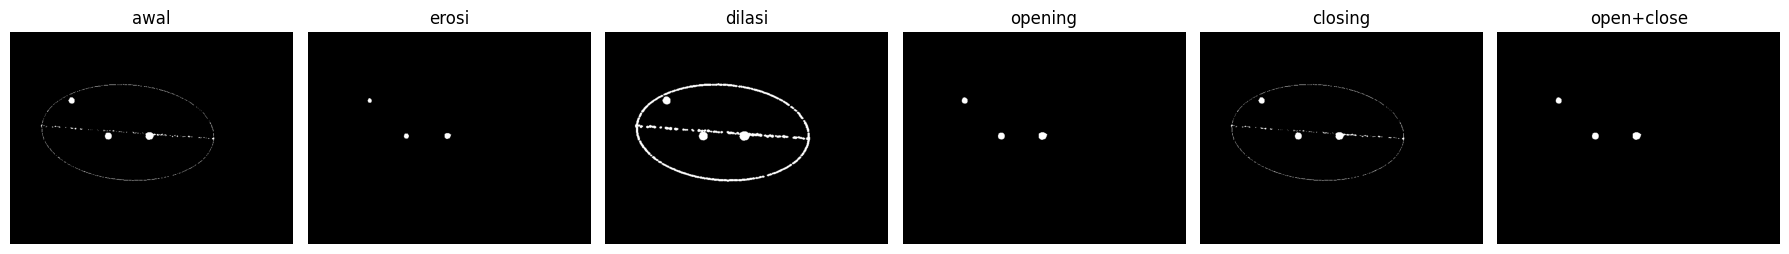

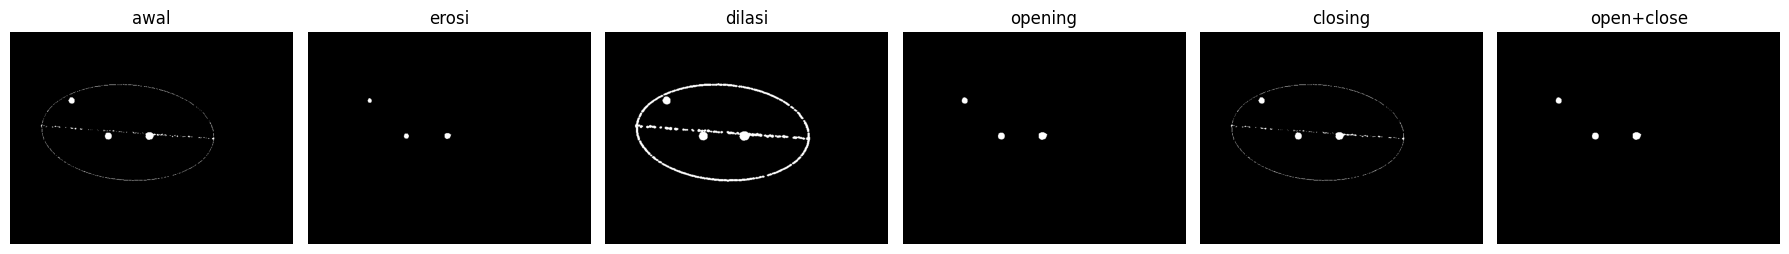

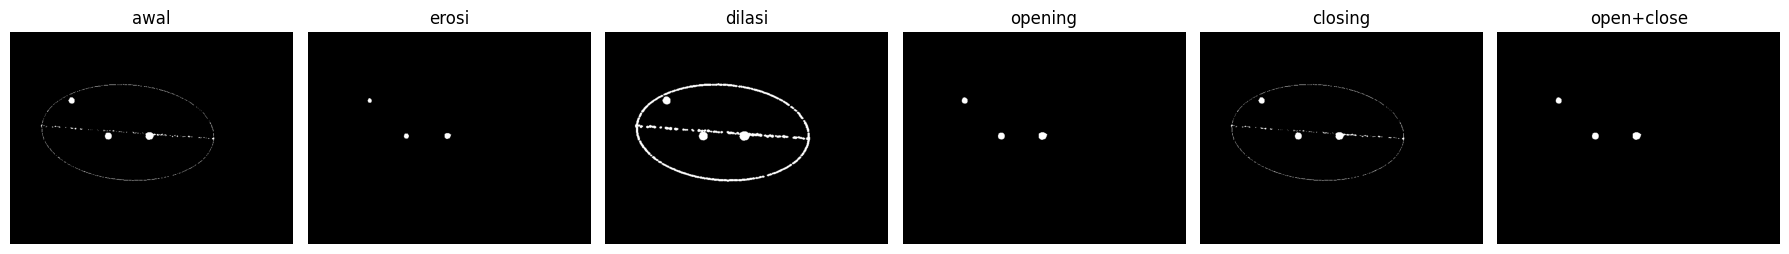

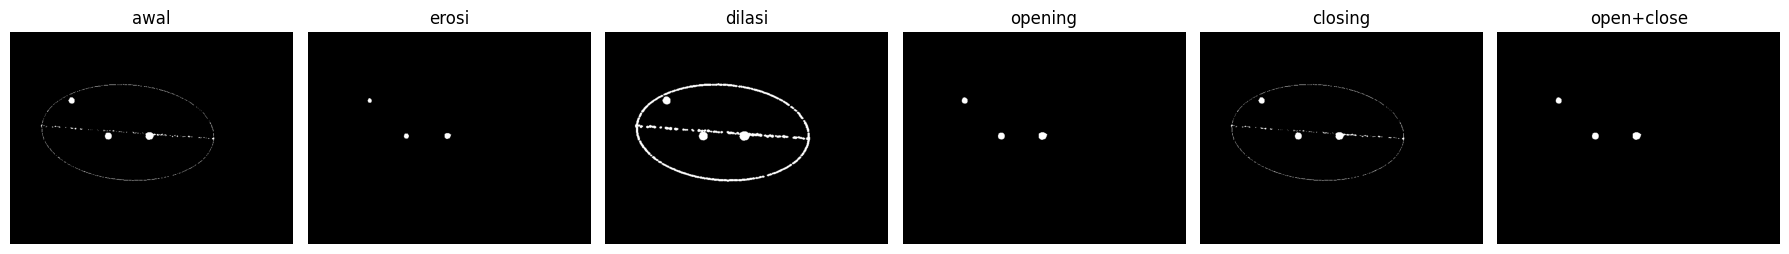

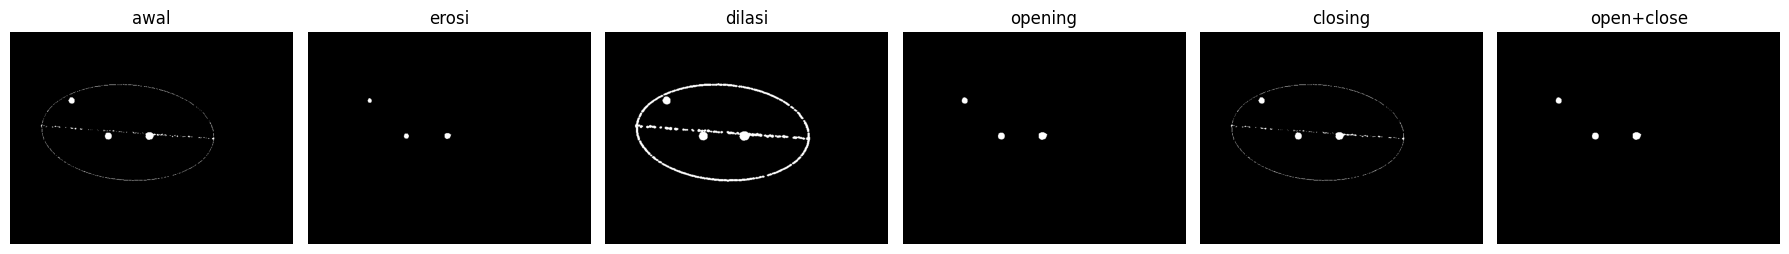

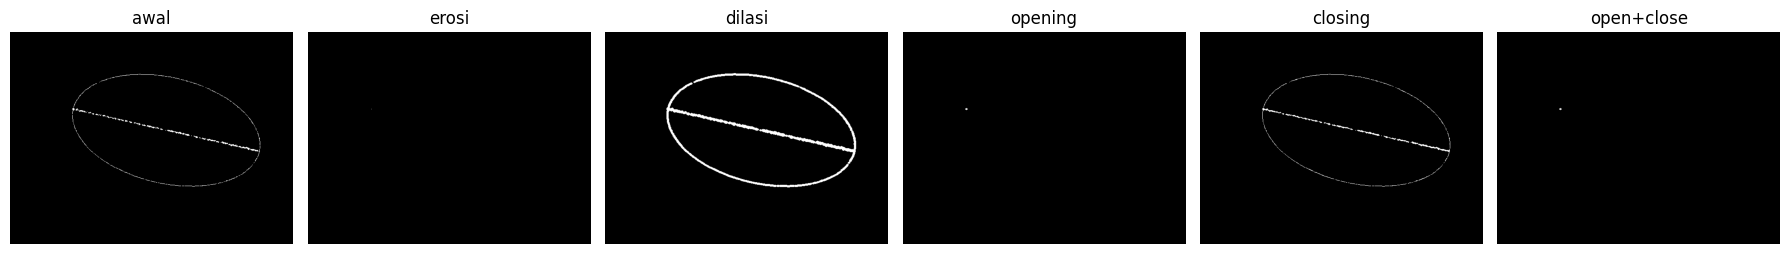

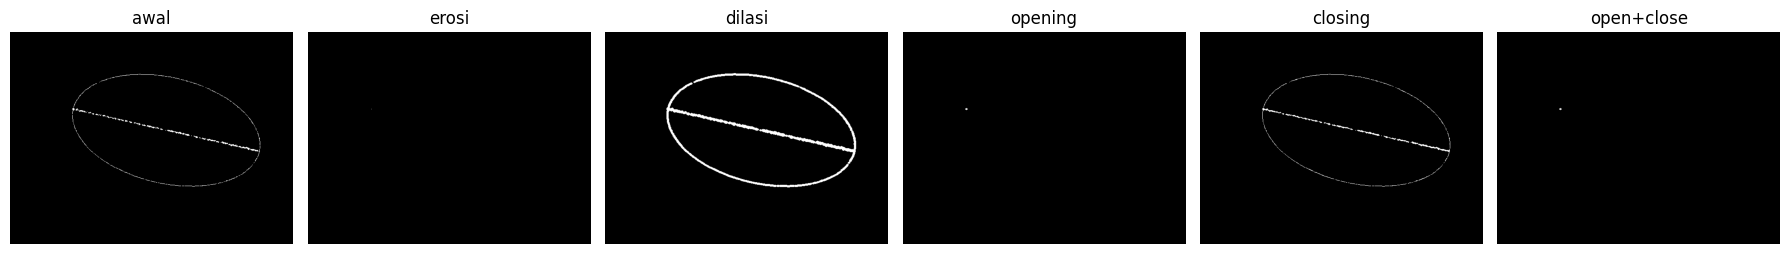

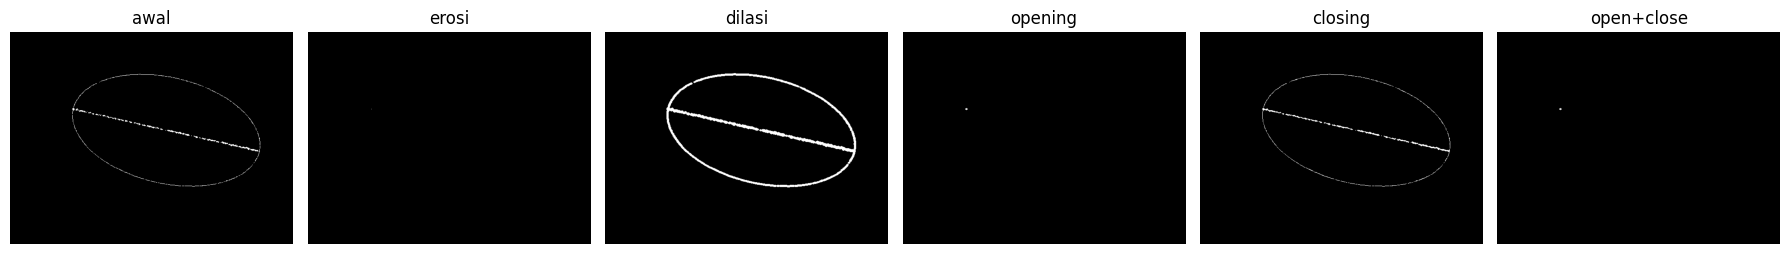

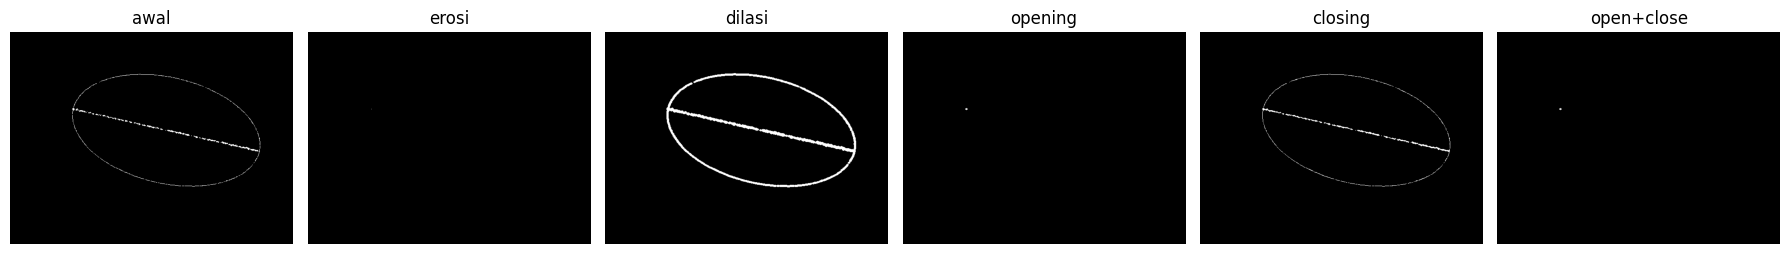

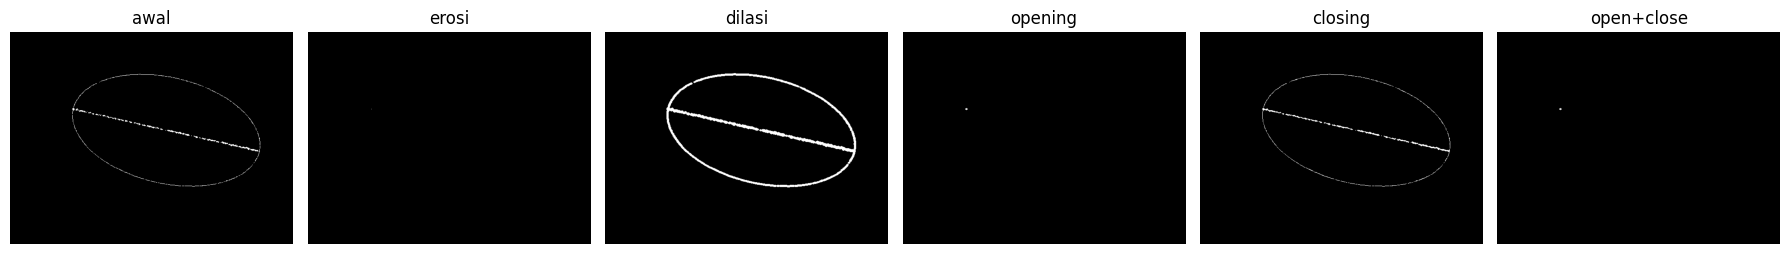

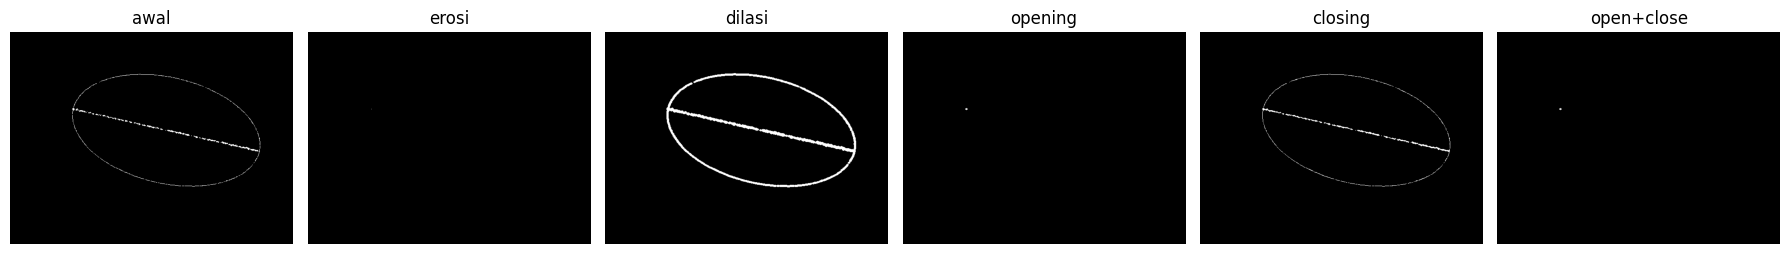

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       217    1498  0.384
1   teh_021.png       erosi         3     327  0.546
2   teh_021.png      dilasi        23    6750  0.089
3   teh_021.png     opening         3     594  0.934
4   teh_021.png     closing       196    1571  0.366
5   teh_021.png  open+close         3     594  0.934
6   teh_011.png        awal       134    1860      -
7   teh_011.png       erosi         1       1      -
8   teh_011.png      dilasi         1    8006      -
9   teh_011.png     opening         1      17      -
10  teh_011.png     closing        95    2022      -
11  teh_011.png  open+close         1      17      -


In [53]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k,k))
def operasi(b, se):
  return {"awal": b,
          "erosi": cv2.erode(b, se),
          "dilasi": cv2.dilate(b, se),
          "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
          "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
          "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN,se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
  img, md, mb = muat(nama)
  pra_ = praproses(img, PARAM)
  b0 = bercak_awal(pra_, mask_daun_awal(pra_))
  hasil = operasi(b0, SE(5))
  for nm, m in hasil.items():
    baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                  round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3));
plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel",
"IoU"]))

## Langkah 3.4 Eksperimen ambang dan SE
### Kode 3.3 Eksperimen k, bentuk, dan ukuran SE


In [54]:
bentuk = {
    "persegi": cv2.MORPH_RECT,
    "elips": cv2.MORPH_ELLIPSE,
    "silang": cv2.MORPH_CROSS
}

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)

    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)

        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(
                    cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
                    cv2.MORPH_CLOSE,
                    se
                )

                baris.append([
                    d.kelas,
                    k,
                    nb,
                    uk,
                    abs(jumlah_komponen(m) - n_acuan),
                    iou(m, mb) if mb.any() else np.nan
                ])

eks = pd.DataFrame(
    baris,
    columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"]
)

print(eks.pivot_table(
    index=["k", "bentuk", "ukuran"],
    columns="kelas",
    values=["galat_jumlah", "IoU"]
).round(2))

# Simpan hasil eksperimen ke folder hasil proyek
os.makedirs(HASIL, exist_ok=True)

file_hasil = os.path.join(HASIL, "p6_eksperimen_se.csv")
eks.to_csv(file_hasil, index=False)

print("Hasil eksperimen berhasil disimpan:", file_hasil)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.73   0.39        14.40  14.20  25.60
          5       0.77   0.56         2.60   2.50   5.80
          7       0.80   0.66         0.65   1.75   1.05
  persegi 3       0.74   0.43         7.15   8.70   8.35
          5       0.79   0.61         1.60   1.15   2.15
          7       0.78   0.69         0.70   0.35   0.05
  silang  3       0.73   0.39        14.40  14.20  25.60
          5       0.77   0.54         5.45   4.45   9.20
          7       0.80   0.65         1.25   2.55   2.45
4 elips   3       0.78   0.57         7.35   6.90  25.10
          5       0.80   0.64         2.20   0.55   2.40
          7       0.79   0.69         0.60   0.55   0.15
  persegi 3       0.78   0.63         3.60   1.75   6.85
          5       0.80   0.63         0.60   2.30   1.25
          7       0.77   0.67  

## Langkah 3.5 Gradien morfologi sebagai tepi daun
### Kode 3.4 Gradien morfologi dibandingkan dengan Canny

In [55]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)

    baris.append([
        d.kondisi_cahaya,
        skor_tepi(grad, ad)[2],
        skor_tepi(canny, ad)[2]
    ])

print(
    pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
    .groupby("kondisi")
    .mean()
    .round(3)
)

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.884     0.657
gelap                          0.971     0.678
kontras_rendah                 0.283     0.854
normal                         0.992     0.700
terang                         0.975     0.732


## Langkah 3.6 elemen SE persegi, elips, dan silang berukuran 3, 5, dan 7 dengan cv2.getStructuringElement dalam satu panel

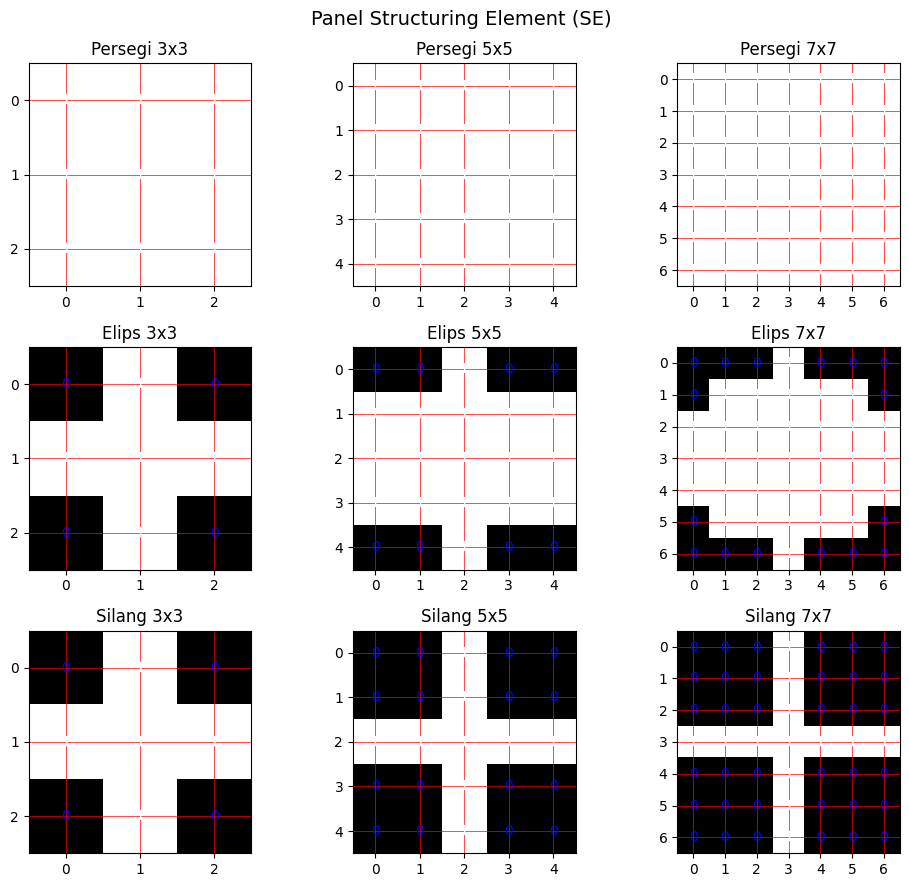

In [56]:

bentuk = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

ukuran = [3, 5, 7]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for i, (nama, kode) in enumerate(bentuk.items()):
    for j, uk in enumerate(ukuran):
        se = cv2.getStructuringElement(kode, (uk, uk))

        axes[i, j].imshow(se, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(f"{nama} {uk}x{uk}")
        axes[i, j].set_xticks(range(uk))
        axes[i, j].set_yticks(range(uk))
        axes[i, j].grid(True, color="red", linewidth=0.5)

        for y in range(uk):
            for x in range(uk):
                axes[i, j].text(
                    x, y, str(se[y, x]),
                    ha="center", va="center",
                    color="blue" if se[y, x] == 0 else "white"
                )

plt.suptitle("Panel Structuring Element (SE)", fontsize=14)
plt.tight_layout()
plt.show()


**P3.1**
Erosi dan opening menghapus bercak berlubang karena syarat operasi erosi dengan structuring element (SE) 3x3 adalah seluruh area yang tertutup SE harus bernilai 1 (putih). Karena bercak 3x3 pada lembar hitung memiliki lubang bernilai 0 di tengahnya, SE tidak akan pernah bisa menempati area tersebut secara penuh, sehingga seluruh bercak terhapus.

Saat dilakukan closing, terjadi penutupan celah di mana lubang di tengah bercak terisi, piksel diagonal yang terpisah menjadi menyatu, dan garis yang terputus menjadi tersambung. Hal ini berisiko bagi SIMUTEH karena jika dua bercak yang berdekatan (hanya berseberangan diagonal atau berjarak sangat dekat) terkena operasi closing, mereka akan melebur menjadi satu komponen. Akibatnya, sistem akan salah menghitung jumlah bercak (menjadi lebih sedikit) dan luas area yang dihitung menjadi lebih besar karena rongga di antaranya ikut terisi.

**P3.2**
Konektivitas 8 lebih tepat digunakan. Pada matriks B di lembar hitung, jika menggunakan konektivitas 4, piksel yang bersentuhan secara diagonal tidak dianggap terhubung dengan blok utama, sehingga jumlah komponen menjadi 4. Dengan konektivitas 8, piksel diagonal tersebut dianggap menyatu, menghasilkan 3 komponen (lebih akurat).

Alasan dari sisi bentuk bercak nyata: bercak pada daun umumnya berbentuk bulat atau tidak beraturan dengan tepi melengkung. Pada citra digital, tepi melengkung sering direpresentasikan sebagai piksel yang bersentuhan secara diagonal. Jika menggunakan konektivitas 4, satu bercak utuh bisa terpecah menjadi beberapa fragmen, sehingga jumlah bercak akan terhitung jauh lebih banyak dari yang seharusnya.

**P3.3**
Opening berhasil membuang derau dan tepi daun karena langkah pertamanya adalah erosi. Erosi akan menghapus objek yang ukurannya lebih kecil dari SE (seperti titik derau dan garis tepi tipis). Dilasi setelahnya hanya mengembalikan objek yang lolos erosi, sehingga derau tetap hilang.

Sebaliknya, closing hampir tidak mengurangi komponen karena langkah pertamanya adalah dilasi, yang justru memperbesar titik derau. Saat erosi dilakukan, derau yang sudah membesar tersebut mungkin tidak hilang sepenuhnya atau malah menyatu dengan komponen lain.

Potongan tulang daun pada daun sehat masih tersisa setelah opening karena ukuran (ketebalan) tulang daun tersebut mungkin lebih besar daripada ukuran SE yang digunakan (misal SE 5x5), atau tulang daun tersebut menyatu langsung dengan batas tepi daun, sehingga erosi tidak mampu menghapusnya.

**P3.4**
Berdasarkan Tabel 9, kombinasi terbaik adalah k=6, bentuk Persegi, ukuran 5. Kombinasi ini memberikan galat jumlah sebesar 0.00 untuk daun sehat (tidak ada bercak palsu), serta galat yang sangat rendah untuk kelas berat (0.45) dan ringan (0.25).

1. Trade-off yang terjadi:

* Jika memilih SE kecil (3x3), bercak kelas ringan (kecil) akan tetap dipertahankan, tetapi banyak bercak palsu (tulang daun/derau) yang ikut terhitung pada daun sehat (galat sehat mencapai 25.60).

* Jika memilih SE besar (7x7), bercak palsu pada daun sehat hilang sepenuhnya (galat 0), tetapi bercak kelas ringan banyak yang ikut tererosi dan hilang (IoU ringan turun, galat ringan naik).

Hasil SE elips 3x3 identik dengan SE silang 3x3 karena pada resolusi grid yang sangat kecil (3x3 piksel), bentuk geometris elips tidak memiliki cukup ruang untuk membentuk lengkungan. Bentuk elips tersebut pada dasarnya hanya mengisi piksel tengah dan empat piksel ortogonal (atas, bawah, kiri, kanan), yang strukturnya sama persis dengan SE silang.

**P3.5**
Gradien morfologi dari mask daun memberi tepi yang lebih baik pada kondisi bayangan, gelap, normal, dan terang karena ia bekerja pada mask biner (hasil segmentasi ambang Otsu pada kanal Saturasi), bukan pada gradien intensitas piksel citra. Selama mask berhasil memisahkan daun dari latar, tepi yang dihasilkan akan sangat tegas, solid, dan kebal terhadap noise permukaan daun.

Namun, pada kondisi kontras rendah, gradien morfologi justru gagal (F1 0.283) sedangkan Canny bagus (F1 0.854). Ini terjadi karena pada kontras rendah, perbedaan Saturasi antara daun dan latar sangat tipis, sehingga mask_daun_awal gagal membuat mask yang benar. Mask yang buruk menghasilkan gradien morfologi yang buruk.

Canny tetap diperlukan dalam dua situasi:

1. Ketika segmentasi awal pembuatan mask gagal, seperti pada kasus citra kontras rendah.

2. Canny sangat diperlukan untuk mendeteksi tepi bercak di dalam daun. Gradien morfologi pada mask daun hanya memberikan tepi luar daun, ia tidak akan bisa mendeteksi batas bercak yang ada di permukaan daun.

# Bagian 4. Komponen Terhubung dan Pengukuran Bercak

## Langkah 4.1 Lembar hitung manual

In [57]:

import cv2
import numpy as np
import pandas as pd
import math

# Konversi ukuran piksel ke milimeter
MM_PER_PX = 0.4375

# Citra biner B dari Langkah 3.1
B = np.array([
    [0,0,0,0,0,0,0,0,0],
    [0,1,1,1,0,0,0,0,0],
    [0,1,0,1,0,0,0,1,0],
    [0,1,1,1,0,0,0,0,0],
    [0,0,0,0,1,0,0,0,0],
    [0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0],
    [0,1,1,1,1,1,1,0,0],
    [0,0,0,0,0,0,0,0,0]
], dtype=np.uint8)

# Structuring Element persegi 3x3
SE = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

# Hasil closing kemudian opening (Langkah 3.1 butir d)
hasil_closing = cv2.morphologyEx(
    B, cv2.MORPH_CLOSE, SE,
    borderType=cv2.BORDER_CONSTANT,
    borderValue=0
)

hasil_d = cv2.morphologyEx(
    hasil_closing, cv2.MORPH_OPEN, SE,
    borderType=cv2.BORDER_CONSTANT,
    borderValue=0
)

# Menghitung keliling berdasarkan jumlah sisi
# piksel yang berbatasan dengan latar
def hitung_keliling(mask):
    mask = mask.astype(np.uint8)
    tinggi, lebar = mask.shape
    keliling = 0

    for y in range(tinggi):
        for x in range(lebar):
            if mask[y, x] == 1:

                if y == 0 or mask[y-1, x] == 0:
                    keliling += 1

                if y == tinggi-1 or mask[y+1, x] == 0:
                    keliling += 1

                if x == 0 or mask[y, x-1] == 0:
                    keliling += 1

                if x == lebar-1 or mask[y, x+1] == 0:
                    keliling += 1

    return keliling

# Menghitung luas, keliling, kebulatan, dan rasio aspek
def ukur_manual(mask, nama):

    luas = int(np.count_nonzero(mask))
    keliling = hitung_keliling(mask)

    luas_mm2 = luas * (MM_PER_PX ** 2)

    kebulatan = (
        4 * math.pi * luas / (keliling ** 2)
        if keliling > 0 else 0
    )

    koordinat_y, koordinat_x = np.where(mask > 0)

    tinggi = koordinat_y.max() - koordinat_y.min() + 1
    lebar = koordinat_x.max() - koordinat_x.min() + 1

    rasio_aspek = max(lebar, tinggi) / min(lebar, tinggi)

    return [
        nama,
        luas,
        round(luas_mm2, 2),
        keliling,
        round(kebulatan, 3),
        round(rasio_aspek, 2)
    ]

# Mengambil bercak 3x3 dari hasil closing + opening
bercak_3x3 = hasil_d[1:4, 0:3]

# Mengambil garis 1x6 dari baris ke-8 citra B
garis_1x6 = B[7:8, 1:7]

# Menghitung kedua objek
hasil = [
    ukur_manual(bercak_3x3, "Bercak 3x3"),
    ukur_manual(garis_1x6, "Garis 1x6")
]

tabel = pd.DataFrame(
    hasil,
    columns=[
        "Objek",
        "Luas (px)",
        "Luas (mm2)",
        "Keliling (px)",
        "Kebulatan",
        "Rasio aspek"
    ]
)

print("=== HASIL LEMBAR HITUNG 4.1 ===")
display(tabel)

print("\n=== HASIL CLOSING + OPENING ===")
print(hasil_d)

print("\n=== KESIMPULAN BENTUK ===")
print("Bercak 3x3 memiliki bentuk lebih kompak dan rasio aspek mendekati 1.")
print("Garis 1x6 memiliki bentuk memanjang dan rasio aspek lebih besar.")


=== HASIL LEMBAR HITUNG 4.1 ===


,Objek,Luas (px),Luas (mm2),Keliling (px),Kebulatan,Rasio aspek
0,Bercak 3x3,6,1.15,10,0.754,1.5
1,Garis 1x6,6,1.15,14,0.385,6.0



=== HASIL CLOSING + OPENING ===
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

=== KESIMPULAN BENTUK ===
Bercak 3x3 memiliki bentuk lebih kompak dan rasio aspek mendekati 1.
Garis 1x6 memiliki bentuk memanjang dan rasio aspek lebih besar.



### Langkah 4.2 Label dan ukur
### Kode 4.1 Komponen terhubung dan pengukuran setiap bercak

konektivitas 4: 29 komponen
konektivitas 8: 29 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      819    156.76        105.5       0.92         1.03  398  174
1       2     1542    295.15        183.7       0.57         1.92  173  209
2       3       54     10.34         34.5       0.57         3.23  515  194
3       4       76     14.55         51.0       0.37         5.09  492  201
4       5       64     12.25         39.3       0.52         3.75  463  210
5       6       37      7.08         25.7       0.71         2.50  446  215
6       7        9      1.72          8.0       1.77         1.00  432  219
7       8       24      4.59         16.8       1.06         2.00  419  222
8       9       15      2.87         12.0       1.31         2.00  410  225
9      10      575    110.06        122.7       0.48         1.47  321  241
10     11       44      8.42         29.1       0.65         2.85  393  230
11     12       74     14.16    

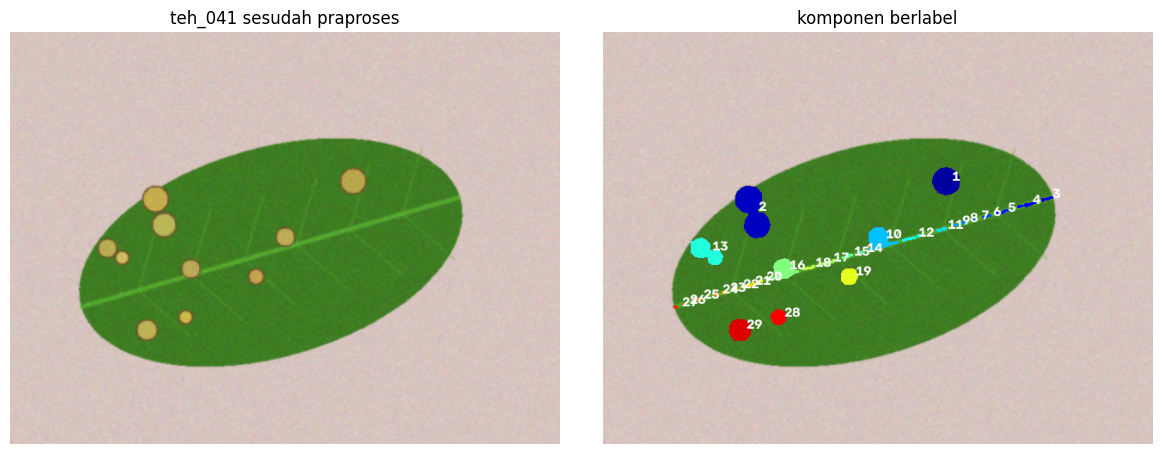

In [58]:
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )
    baris = []

    for i in range(1, n):
        kontur, _ = cv2.findContours(
            (lbl == i).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE
        )
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)

        baris.append([
            i,
            A,
            round(A * MM_PER_PX ** 2, 2),
            round(keliling, 1),
            round(kebulatan, 2),
            round(rasio, 2),
            int(cen[i][0]),
            int(cen[i][1])
        ])

    kolom = [
        "label",
        "luas_px",
        "luas_mm2",
        "keliling_px",
        "kebulatan",
        "rasio_aspek",
        "cx",
        "cy"
    ]

    return pd.DataFrame(baris, columns=kolom), lbl


img, md, mb = muat("teh_041.png")

pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)

bersih = cv2.morphologyEx(
    cv2.morphologyEx(
        bercak_awal(pra_, m_daun),
        cv2.MORPH_OPEN,
        SE
    ),
    cv2.MORPH_CLOSE,
    SE
)

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap(
    (lbl * (255 // max(lbl.max(), 1))).astype(np.uint8),
    cv2.COLORMAP_JET
)

warna[lbl == 0] = pra_[lbl == 0]

for _, r in tabel_kom.iterrows():
    cv2.putText(
        warna,
        str(int(r.label)),
        (int(r.cx) + 8, int(r.cy)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        2
    )

tampil(
    [pra_, warna],
    ["teh_041 sesudah praproses", "komponen berlabel"],
    ukuran=(12, 4.5)
)

## Langkah 4.3 Saring bercak palsu
### Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk

In [59]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)

    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)
    ]

    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos


aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}

baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE
        ),
        cv2.MORPH_CLOSE,
        SE
    )

    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([
    d.kelas,
    nm,
    jumlah_komponen(f, 8),
    jumlah_komponen(mb, 8)
])

uji = pd.DataFrame(
    baris,
    columns=["kelas", "aturan", "jumlah", "acuan"]
)

uji["galat"] = (uji.jumlah - uji.acuan).abs()

print("=== GALAT JUMLAH KOMPONEN ===")
print(
    uji.pivot_table(
        index="aturan",
        columns="kelas",
        values="galat"
    ).round(2)
)

print("\nDaun sehat yang masih memiliki bercak palsu:")
print(
    uji[uji.kelas == "sehat"]
    .assign(palsu=lambda t: t.jumlah > 0)
    .groupby("aturan")
    .palsu.sum()
)

=== GALAT JUMLAH KOMPONEN ===
kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan            1.7    0.10   1.45
luas + kebulatan + rasio    0.9    0.05   0.20
luas >= 20                  2.2    0.25   2.55
tanpa saring                3.6    1.75   6.85

Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             6
luas + kebulatan + rasio     2
luas >= 20                   8
tanpa saring                14
Name: palsu, dtype: int64


## Langkah 4.4 dasar ambang penyaringan.

=== HASIL KLASIFIKASI KOMPONEN ===
status
palsu    240
benar    198
Name: count, dtype: int64

=== RINGKASAN BERDASARKAN STATUS ===
       luas_px                   kebulatan                   rasio_aspek  \
         count    mean min   max     count  mean   min   max       count   
status                                                                     
benar      198  394.15   9  1542       198  0.92  0.11  1.77         198   
palsu      240   73.55   6  2185       240  1.25  0.03  2.09         240   

                          
        mean  min    max  
status                    
benar   1.12  1.0   3.65  
palsu   3.65  1.0  72.28  


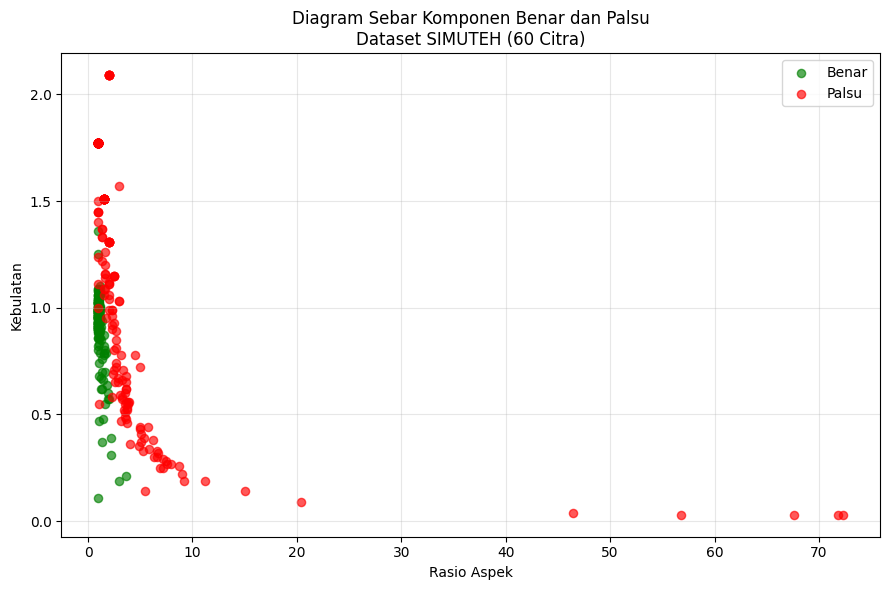


=== CONTOH DATA KOMPONEN ===


,nama_file,kelas,label,luas_px,kebulatan,rasio_aspek,proporsi_acuan,status
0,teh_001.png,sehat,1,9,1.77,1.0,0.0,palsu
1,teh_003.png,sehat,1,2044,0.03,67.6,0.0,palsu
2,teh_004.png,sehat,1,6,2.09,2.0,0.0,palsu
3,teh_004.png,sehat,2,6,2.09,2.0,0.0,palsu
4,teh_004.png,sehat,3,8,1.57,3.0,0.0,palsu
5,teh_004.png,sehat,4,6,2.09,2.0,0.0,palsu
6,teh_004.png,sehat,5,9,1.77,1.0,0.0,palsu
7,teh_004.png,sehat,6,9,1.77,1.0,0.0,palsu
8,teh_004.png,sehat,7,9,1.77,1.0,0.0,palsu
9,teh_004.png,sehat,8,9,1.77,1.0,0.0,palsu



Hasil disimpan: /content/drive/MyDrive/simuteh-2330511004/hasil/p6_dasar_ambang_penyaringan.csv


In [60]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Menampung seluruh komponen dari 60 citra
data_komponen = []

for _, d in label.iterrows():

    # Memuat citra dan mask acuan
    img, md, mb = muat(d.nama_file)

    # Praproses
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    # Pembersihan bercak dengan opening dan closing
    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE
        ),
        cv2.MORPH_CLOSE,
        SE
    )

    # Mengukur setiap komponen
    tabel_k, lbl = ukur_komponen(bersih)

    # Mask bercak acuan
    mask_acuan = mb > 0

    for _, k in tabel_k.iterrows():

        nomor = int(k.label)

        # Mengambil piksel dari satu komponen
        komponen = (lbl == nomor)

        # Menghitung persentase piksel yang tumpang tindih
        # dengan mask bercak acuan
        total_piksel = np.count_nonzero(komponen)
        piksel_acuan = np.count_nonzero(
            komponen & mask_acuan
        )

        proporsi = (
            piksel_acuan / total_piksel
            if total_piksel > 0 else 0
        )

        # Benar jika lebih dari separuh piksel berada
        # di dalam mask bercak acuan
        status = "benar" if proporsi > 0.5 else "palsu"

        data_komponen.append([
            d.nama_file,
            d.kelas,
            nomor,
            int(k.luas_px),
            float(k.kebulatan),
            float(k.rasio_aspek),
            round(proporsi, 3),
            status
        ])

# Membuat DataFrame hasil
hasil_komponen = pd.DataFrame(
    data_komponen,
    columns=[
        "nama_file",
        "kelas",
        "label",
        "luas_px",
        "kebulatan",
        "rasio_aspek",
        "proporsi_acuan",
        "status"
    ]
)

# Menampilkan jumlah komponen benar dan palsu
print("=== HASIL KLASIFIKASI KOMPONEN ===")
print(
    hasil_komponen["status"].value_counts()
)

print("\n=== RINGKASAN BERDASARKAN STATUS ===")
print(
    hasil_komponen.groupby("status")[
        ["luas_px", "kebulatan", "rasio_aspek"]
    ].agg(["count", "mean", "min", "max"]).round(2)
)

# Diagram sebar kebulatan terhadap rasio aspek
plt.figure(figsize=(9, 6))

warna = {
    "benar": "green",
    "palsu": "red"
}

for status in ["benar", "palsu"]:

    data = hasil_komponen[
        hasil_komponen.status == status
    ]

    plt.scatter(
        data["rasio_aspek"],
        data["kebulatan"],
        c=warna[status],
        label=status.capitalize(),
        alpha=0.65,
        s=35
    )

plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.title(
    "Diagram Sebar Komponen Benar dan Palsu\n"
    "Dataset SIMUTEH (60 Citra)"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Menampilkan beberapa baris hasil
print("\n=== CONTOH DATA KOMPONEN ===")
display(hasil_komponen.head(10))

# Menyimpan hasil
file_hasil = os.path.join(
    HASIL,
    "p6_dasar_ambang_penyaringan.csv"
)

hasil_komponen.to_csv(file_hasil, index=False)

print("\nHasil disimpan:", file_hasil)

**P4.1**
Kebulatan bercak 3x3 adalah 0.754, sedangkan garis 1x6 adalah 0.385. Bercak 3x3 tidak sama dengan 1 (lingkaran sempurna) karena representasi pikselnya pada grid digital tidak membentuk kurva mulus, sehingga kelilingnya (10 piksel) relatif lebih besar dibandingkan luasnya (6 piksel).

Pada komponen yang sangat kecil, nilai kebulatan hasil OpenCV bisa lebih dari 1 karena perhitungan keliling menggunakan cv2.arcLength yang berbasis pada titik-titik kontur diskrit, bukan keliling geometris sebenarnya. Untuk objek yang sangat kecil (seperti 1 atau 2 piksel), algoritma penelusuran kontur dapat menghasilkan nilai keliling yang jauh lebih kecil dari seharusnya (underestimate), sehingga saat dimasukkan ke rumus
4
π
A
/
P
2
4πA/P
2
 , nilai pembaginya menjadi sangat kecil dan hasil kebulatan melebihi 1 (seperti terlihat pada diagram sebar yang mencapai nilai > 2.0).

**P4.2**
Asumsi yang mendasari konversi 1 piksel = 0.4375 mm adalah: jarak kamera ke objek (Z) tetap di angka 200 mm, lebar area kerja (working distance) konstan 640 piksel, panjang fokus lensa kamera tetap, dan permukaan daun diasumsikan rata sejajar dengan sensor kamera.

Jika petugas memotret dari jarak 30 cm (300 mm), objek akan terlihat lebih kecil di dalam frame. Jika tetap menggunakan nilai konversi 0.4375 mm/piksel, maka luas bercak dalam mm² akan sangat jauh di bawah nilai sebenarnya (underestimate), karena satu piksel sekarang mewakili area fisik yang lebih besar. Pada foto nyata, SIMUTEH mengatasinya dengan cara melakukan kalibrasi menggunakan objek referensi berukuran pasti (seperti koin atau penanda ArUco) yang diletakkan di samping daun saat pengambilan gambar, atau menggunakan parameter kalibrasi intrinsik kamera (camera matrix) untuk menghitung ulang skala secara dinamis.

**P4.3**
Berdasarkan tabel galat jumlah komponen, aturan yang paling efektif membuang bercak palsu adalah luas + kebulatan + rasio. Aturan ini menghasilkan galat terkecil pada daun sehat (0.20) dan hanya menyisakan 2 daun sehat yang masih memiliki bercak palsu.

Risiko dari penerapan aturan rasio aspek (maksimal 1.8):

1. Bercak memanjang: Jika ada bercak asli yang bentuknya memanjang (bukan bulat sempurna), aturan ini akan salah membuangnya (false negative).

2. Dua bercak menyatu: Jika dua bercak saling berdekatan dan menyatu (terutama setelah operasi closing), bentuk gabungannya akan memanjang dengan rasio aspek yang besar, sehingga bercak asli tersebut bisa ikut tersaring dan hilang dari perhitungan.

**P4.4**
Luas total bercak hasil deteksi hampir dapat dipastikan lebih besar dibandingkan dengan mask acuan. Penyebabnya:

1. Kanal R pada cincin kecokelatan: Proses bercak_awal menggunakan nilai kanal R. Cincin kecokelatan di tepi bercak memiliki nilai R yang tinggi (terang), sehingga piksel cincin ini ikut tertangkap sebagai bagian dari bercak, membuat area melebar.

2. Pengaruh penapis median: Penapis median pada tahap praproses cenderung menghaluskan tepi dan menyebarkan area yang terang, yang secara tidak langsung ikut memperluas jangkauan piksel bercak.

3. Pengaruh closing: Operasi morfologi closing (dilasi lalu erosi) mengisi lubang-lubang kecil dan menyambungkan piksel yang berdekatan. Proses ini menambahkan piksel di sekitar area bercak, sehingga luas total yang terdeteksi menjadi lebih besar daripada kondisi aslinya.

# Bagian 5. Integrasi: Modul Analisis Bercak SIMUTEH


## Langkah 5.1
### Kode 5.1 Kerangka src/bercak.py

Galat absolut rerata persen bercak: 0.396
Korelasi persen prediksi vs acuan : 0.944
Akurasi kelas : 0.933
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             19              0      1
Bercak Ringan             0             19      1
Sehat                     0              2     18
kondisi
bayangan          0.92
gelap             1.00
kontras_rendah    0.92
normal            0.92
terang            0.92
Name: benar, dtype: float64


Text(0, 0.5, 'persen bercak prediksi')

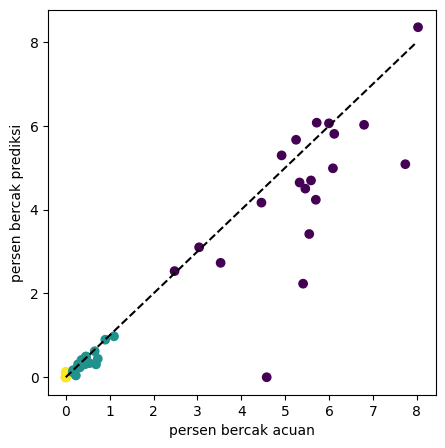

In [61]:
import os
import sys

# 1. Tentukan lokasi folder notebook Anda
# (Sesuaikan path ini jika notebook Anda tidak berada di dalam folder 'notebook')
NOTEBOOK_DIR = "/content/drive/MyDrive/simuteh-2330511004/notebook"

# 2. Pindahkan direktori kerja ke folder tersebut
os.chdir(NOTEBOOK_DIR)

# 3. Tambahkan folder src ke path agar bisa import bercak
sys.path.append("/content/drive/MyDrive/simuteh-2330511004/src")

import importlib
import bercak

importlib.reload(bercak)

PB = {}  # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB) # Ini akan otomatis tersimpan di ../hasil/param_bercak.json

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)

    baris.append([
        d.nama_file,
        d.kelas,
        d.kondisi_cahaya,
        d.persen_bercak,
        h["persen_bercak"],
        jumlah_komponen(mb, 8),
        h["jumlah_bercak"],
        h["kelas"]
    ])

ev = pd.DataFrame(
    baris,
    columns=[
        "nama",
        "kelas",
        "kondisi",
        "persen_acuan",
        "persen_prediksi",
        "jumlah_acuan",
        "jumlah_prediksi",
        "kelas_prediksi"
    ]
)

ev["kelas_acuan"] = ev.kelas.map({
    "sehat": "Sehat",
    "ringan": "Bercak Ringan",
    "berat": "Bercak Berat"
})

# Ini juga akan berhasil karena os.chdir sudah dijalankan
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))

print(pd.crosstab(
    ev.kelas_acuan,
    ev.kelas_prediksi,
    rownames=["acuan"],
    colnames=["prediksi"]
))

print(
    ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan)
    .groupby("kondisi")
    .benar.mean()
    .round(2)
)

plt.figure(figsize=(5, 5))
plt.scatter(
    ev.persen_acuan,
    ev.persen_prediksi,
    c=ev.kelas.astype("category").cat.codes
)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")

Ditemukan 4 citra yang salah kelas. Berikut detailnya:



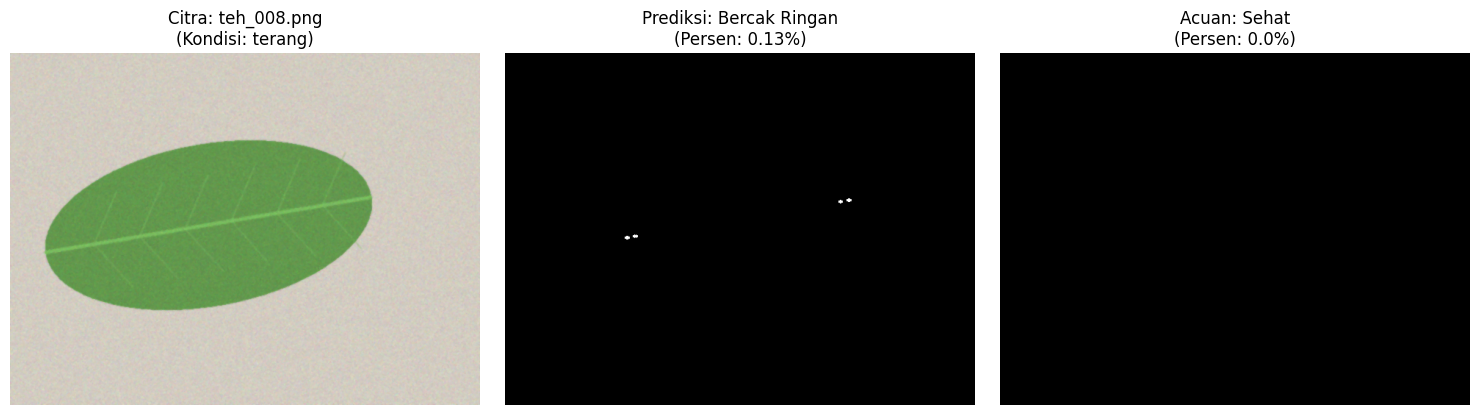

----------------------------------------------------------------------------------------------------



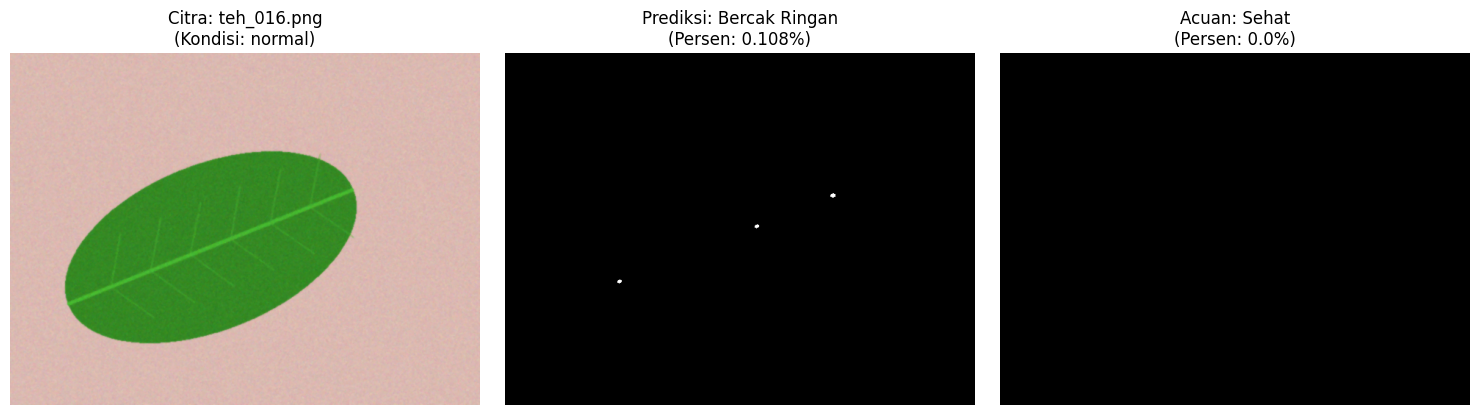

----------------------------------------------------------------------------------------------------



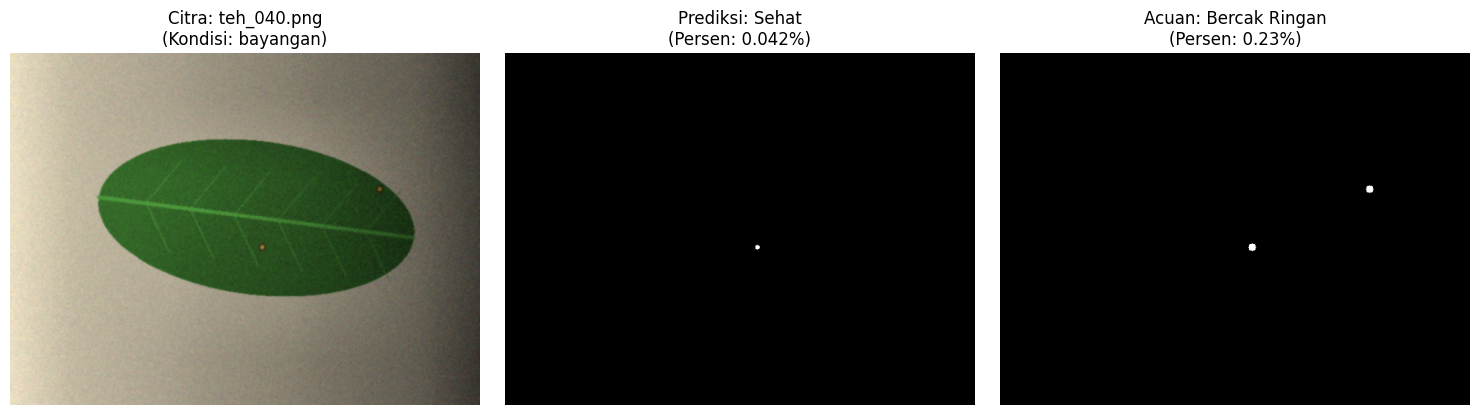

----------------------------------------------------------------------------------------------------



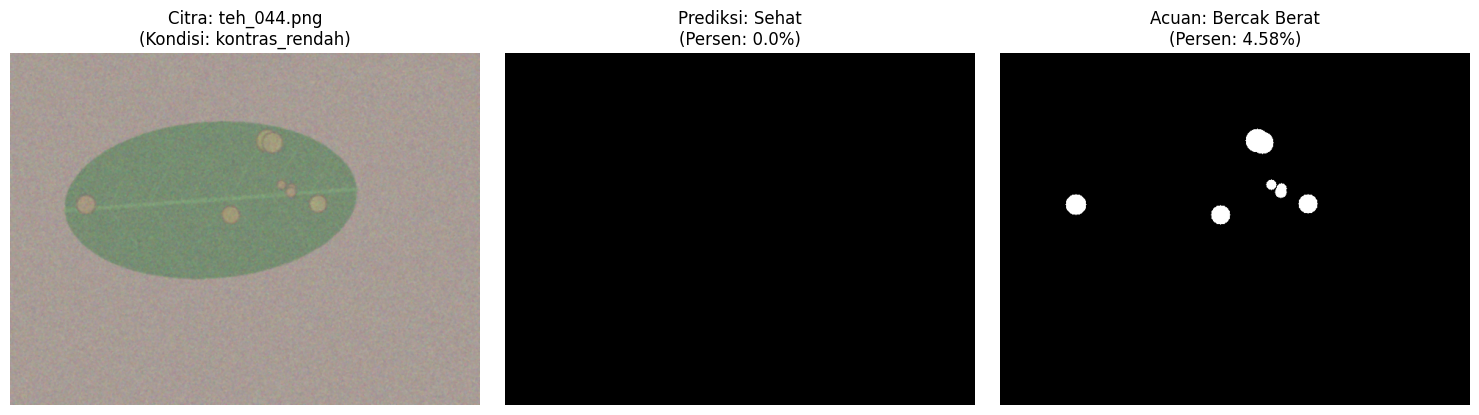

----------------------------------------------------------------------------------------------------



In [62]:
import matplotlib.pyplot as plt
import cv2

# 1. Filter hanya citra yang salah kelas
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]

if len(salah) == 0:
    print("Luar biasa! Tidak ada citra yang salah kelas.")
else:
    print(f"Ditemukan {len(salah)} citra yang salah kelas. Berikut detailnya:\n")

    # 2. Loop untuk setiap citra yang salah
    for _, row in salah.iterrows():
        img, md, mb = muat(row['nama'])
        pra_ = praproses(img, PARAM)
        h = bercak.analisis_daun(pra_, PB)

        # Konversi BGR ke RGB untuk matplotlib
        img_rgb = cv2.cvtColor(pra_, cv2.COLOR_BGR2RGB)

        # Buat plot 1 baris 3 kolom
        fig, ax = plt.subplots(1, 3, figsize=(15, 4))

        # Panel 1: Citra Praproses
        ax[0].imshow(img_rgb)
        ax[0].set_title(f"Citra: {row['nama']}\n(Kondisi: {row['kondisi']})")

        # Panel 2: Mask Prediksi
        ax[1].imshow(h["mask_bercak"], cmap='gray')
        ax[1].set_title(f"Prediksi: {row['kelas_prediksi']}\n(Persen: {h['persen_bercak']}%)")

        # Panel 3: Mask Acuan
        ax[2].imshow(mb, cmap='gray')
        ax[2].set_title(f"Acuan: {row['kelas_acuan']}\n(Persen: {row['persen_acuan']}%)")

        # Hilangkan sumbu x dan y
        for a in ax:
            a.axis('off')

        plt.tight_layout()
        plt.show()
        print("-" * 100 + "\n")

In [63]:

kolom = [
    "nama",
    "kondisi",
    "kelas_acuan",
    "kelas_prediksi",
    "persen_acuan",
    "persen_prediksi",
    "jumlah_acuan",
    "jumlah_prediksi"
]

display(salah[kolom].reset_index(drop=True))


,nama,kondisi,kelas_acuan,kelas_prediksi,persen_acuan,persen_prediksi,jumlah_acuan,jumlah_prediksi
0,teh_008.png,terang,Sehat,Bercak Ringan,0.00,0.130,0,4
1,teh_016.png,normal,Sehat,Bercak Ringan,0.00,0.108,0,3
2,teh_040.png,bayangan,Bercak Ringan,Sehat,0.23,0.042,2,1
3,teh_044.png,kontras_rendah,Bercak Berat,Sehat,4.58,0.000,6,0
